In [1]:
import os, sys
from PIL import Image
from tqdm import tqdm
import yaml


# Add the project root directory to sys.path
project_root = os.path.abspath('../..')  # Adjust this path if needed
sys.path.append(project_root)

from utils import get_images_from_list, create_file_names_list
from utils import mask_on_image, dilate_mask, plot_grid

from inpainting_iopaint_lama_sdxl import inpaint_instance_iopaint_lama_sdxl, setup_diffusion_model

2024-11-03 15:48:12.109370: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-11-03 15:48:12.123847: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-11-03 15:48:12.128244: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-11-03 15:48:12.142422: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-11-03 15:48:13.344619: W tensorflow/compiler/tf2

[11/03/24 15:48:17] WARNING  Your inference package version 0.12.1 is out of date! Please upgrade to ]8;id=233959;file:///usr/local/lib/python3.10/site-packages/inference/core/__init__.py\__init__.py]8;;\:]8;id=900048;file:///usr/local/lib/python3.10/site-packages/inference/core/__init__.py#35\35]8;;\
                             version 0.25 of inference for the latest features and bug fixes by                    
                             running `pip install --upgrade inference`.                                            

## Datasets
### Load ISIC 2019 dataset

In [2]:
# Load the YAML file into a dictionary
dataset_yaml_file = "/workspace/home/data/datasets.yaml"
with open(dataset_yaml_file, "r") as file:
    datasets = yaml.safe_load(file)


# get dataset
dataset_key = "ISIC2019"
dataset = datasets[dataset_key]

## Setup images, custom vocabulary and models

In [3]:
def convert_img_id(img_id):
    # 55292 -> ISIC_0055292.jpg
    # 10 -> ISIC_0000010.jpg
    return f"ISIC_{str(img_id).zfill(7)}.jpg"
mask_ids = [604, 712, 592, 610, 932, 9040, 600]

In [4]:
n = 20
segmentation_id = 'gt'
images_path = dataset["raw_path"]
#segmentation_masks_path = dataset['gt_seg_path']
segmentation_masks_path = f"/workspace/home/pipeline_outputs/{dataset_key}/{segmentation_id}/seg"
mask_names = create_file_names_list(segmentation_masks_path)[:n]
mask_names = [convert_img_id(mask_id) for mask_id in mask_ids]
images = get_images_from_list(mask_names, images_path)
segmentation_masks = get_images_from_list(mask_names, segmentation_masks_path)

prompt = "part of skin in homogenous skin color"
# "remove the colorful patch and replace with skin tissue"

# For dilating the mask
kernel_size = 15
iterations = 10

pipe, generator = setup_diffusion_model(device = 0)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


## Run model on segmentations and visualize the inpainting

  0%|          | 0/7 [00:00<?, ?it/s]2024-11-03 15:48:30.601 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")
/usr/local/lib/python3.10/site-packages/iopaint/model/ldm.py:279: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @torch.cuda.amp.au

  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:0100:01


  0%|          | 0/24 [00:00<?, ?it/s]

Image: ISIC_0000592.jpg


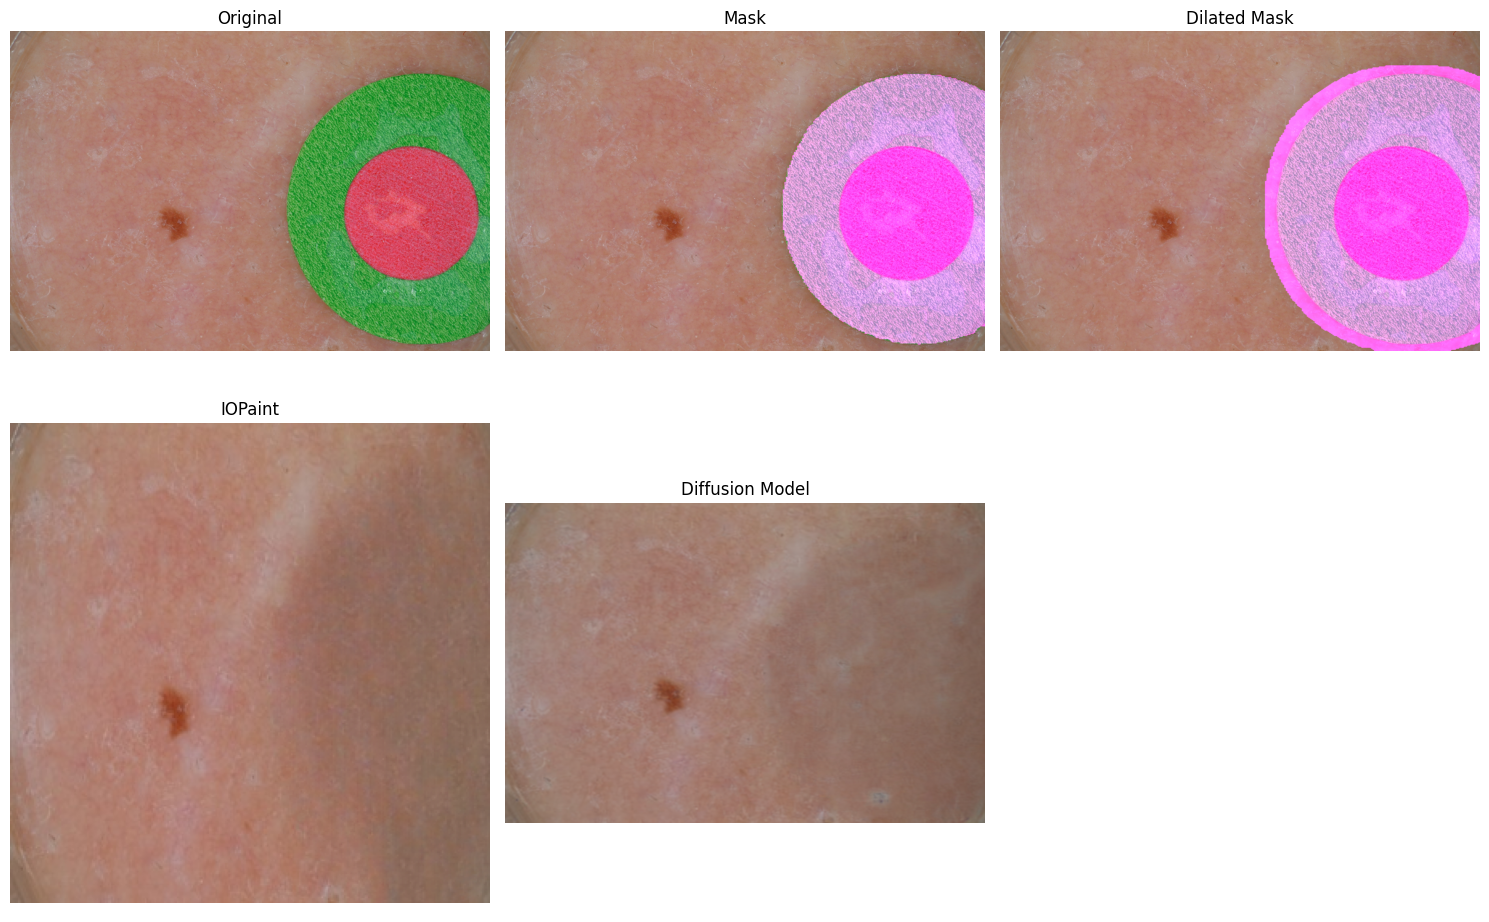

 14%|█▍        | 1/7 [00:20<02:05, 20.96s/it]2024-11-03 15:48:51.502 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")
/usr/local/lib/python3.10/site-packages/iopaint/model/ldm.py:279: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @torch.cud

  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:0100:01


  0%|          | 0/24 [00:00<?, ?it/s]

Image: ISIC_0000600.jpg


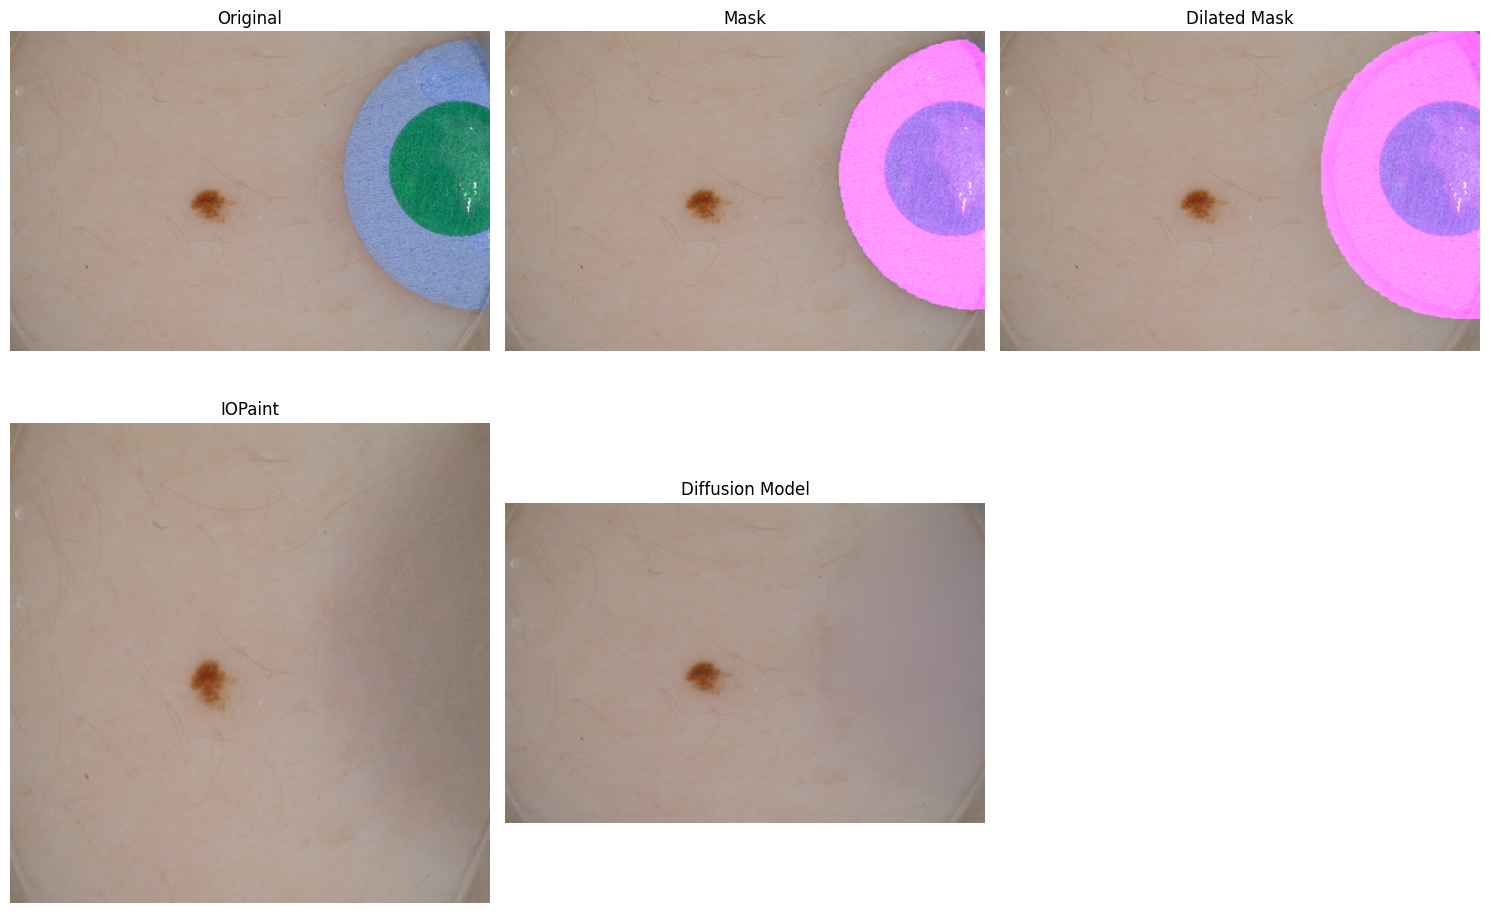

 29%|██▊       | 2/7 [00:39<01:36, 19.31s/it]2024-11-03 15:49:09.662 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")
/usr/local/lib/python3.10/site-packages/iopaint/model/ldm.py:279: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @torch.cud

  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:0100:01


  0%|          | 0/24 [00:00<?, ?it/s]

Image: ISIC_0000604.jpg


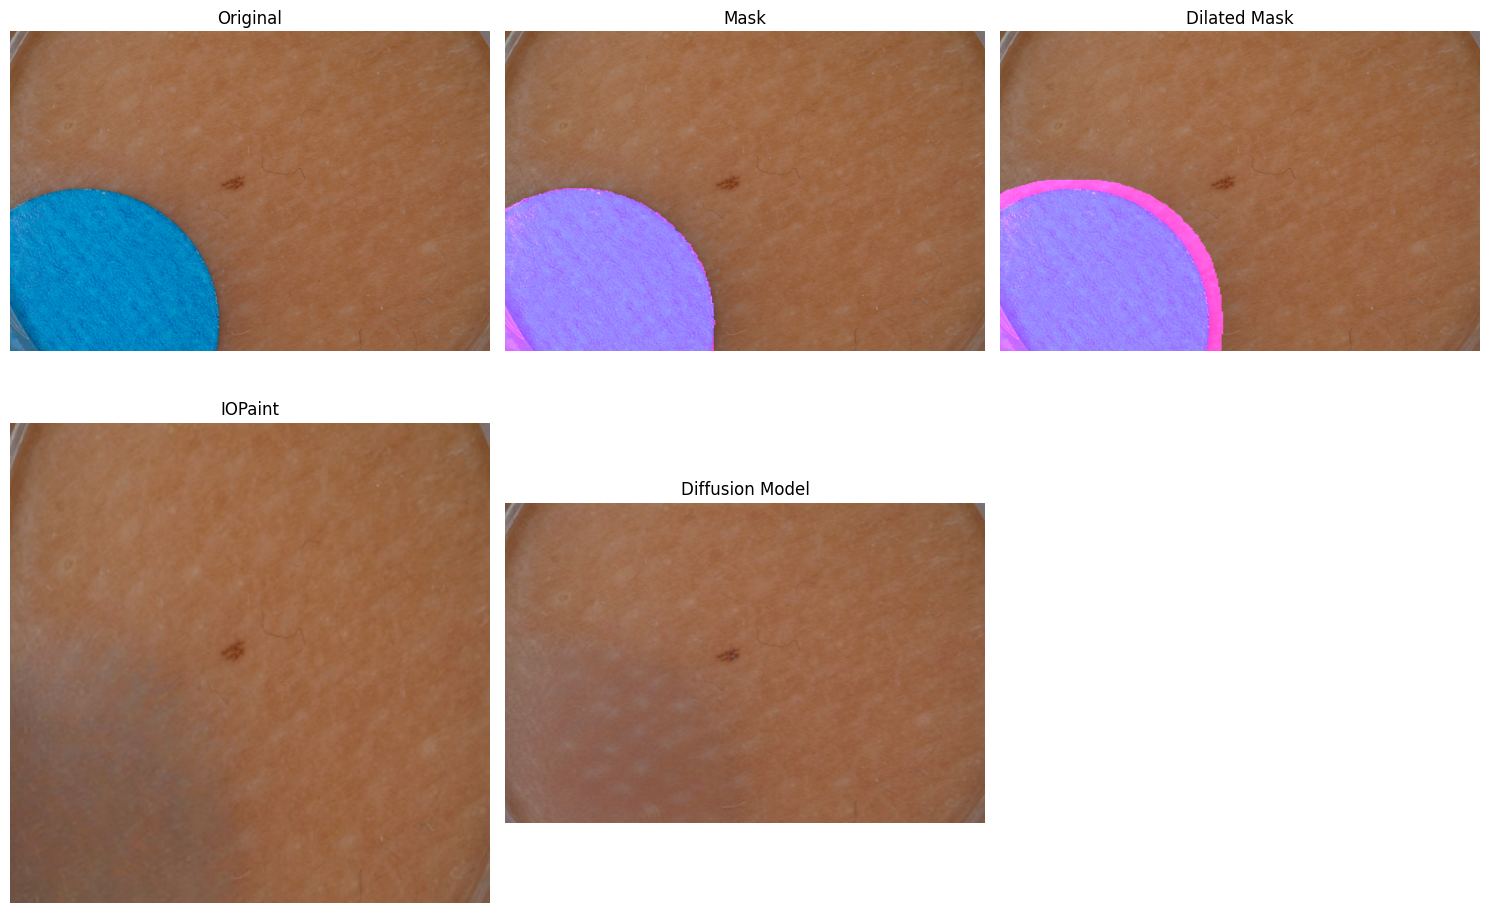

 43%|████▎     | 3/7 [00:58<01:16, 19.17s/it]2024-11-03 15:49:28.639 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")
/usr/local/lib/python3.10/site-packages/iopaint/model/ldm.py:279: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @torch.cud

  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:0100:01


  0%|          | 0/24 [00:00<?, ?it/s]

Image: ISIC_0000610.jpg


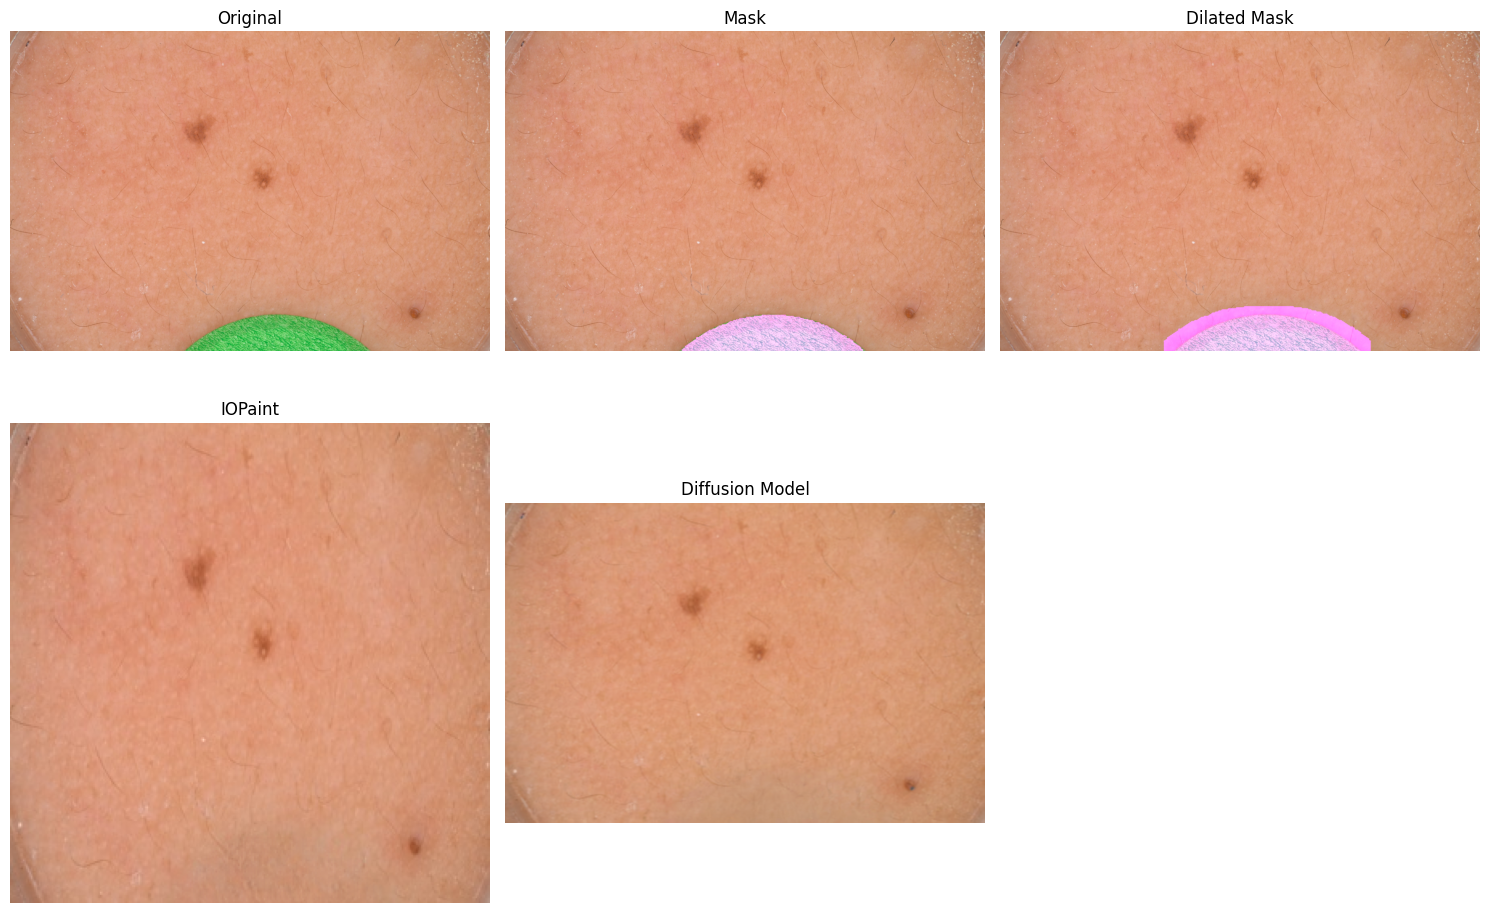

 57%|█████▋    | 4/7 [01:16<00:56, 18.74s/it]2024-11-03 15:49:46.727 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")
/usr/local/lib/python3.10/site-packages/iopaint/model/ldm.py:279: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @torch.cud

  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:0000:00


  0%|          | 0/24 [00:00<?, ?it/s]

Image: ISIC_0000712.jpg


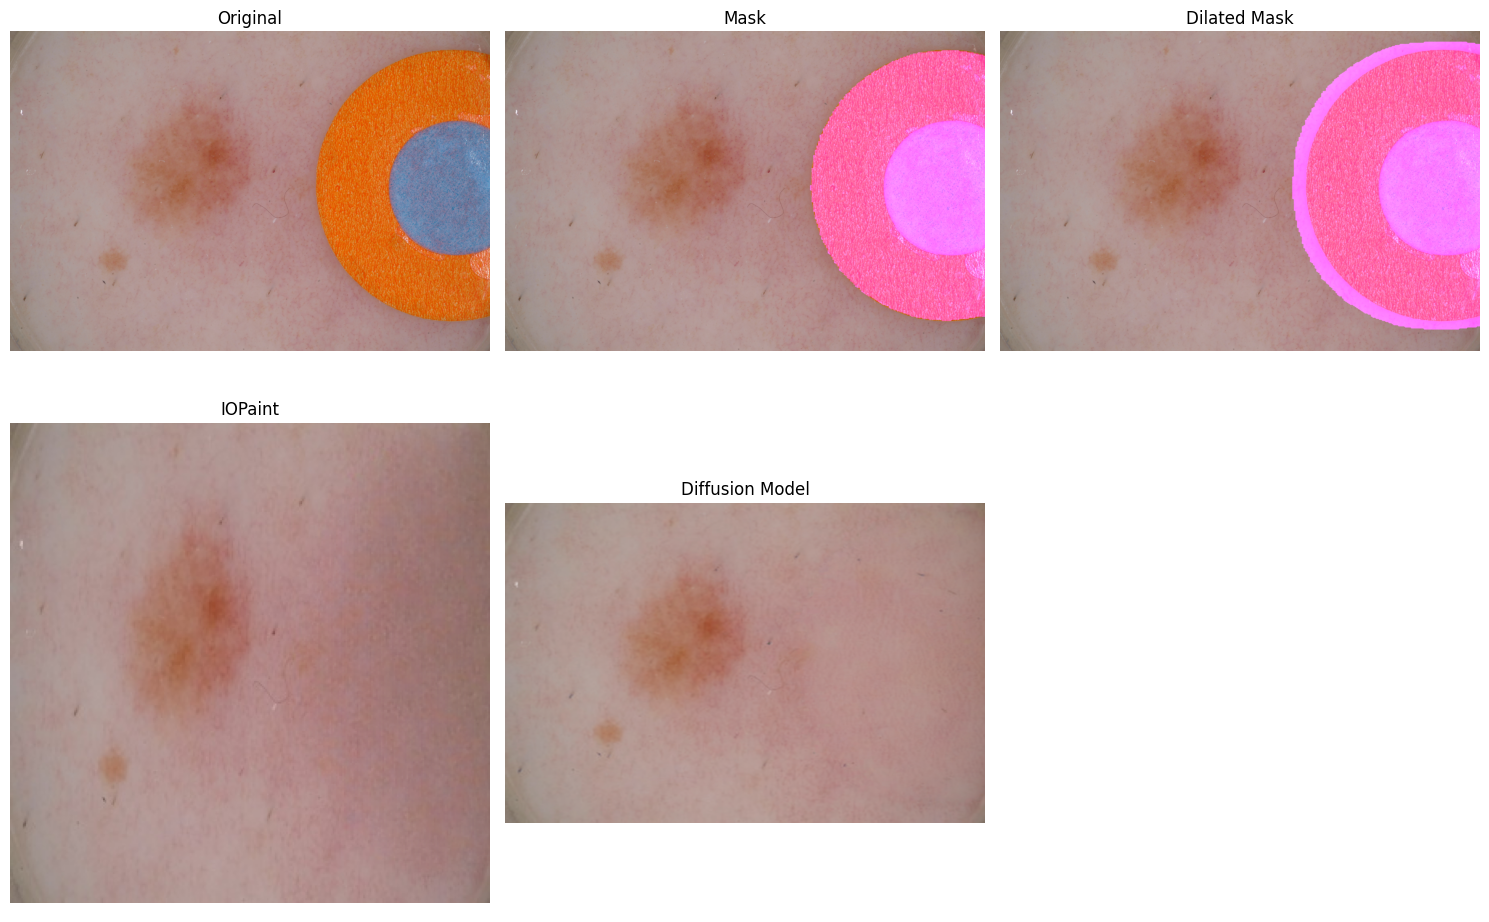

 71%|███████▏  | 5/7 [01:34<00:36, 18.49s/it]2024-11-03 15:50:04.724 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")
/usr/local/lib/python3.10/site-packages/iopaint/model/ldm.py:279: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @torch.cud

  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:0100:00


  0%|          | 0/24 [00:00<?, ?it/s]

Image: ISIC_0000932.jpg


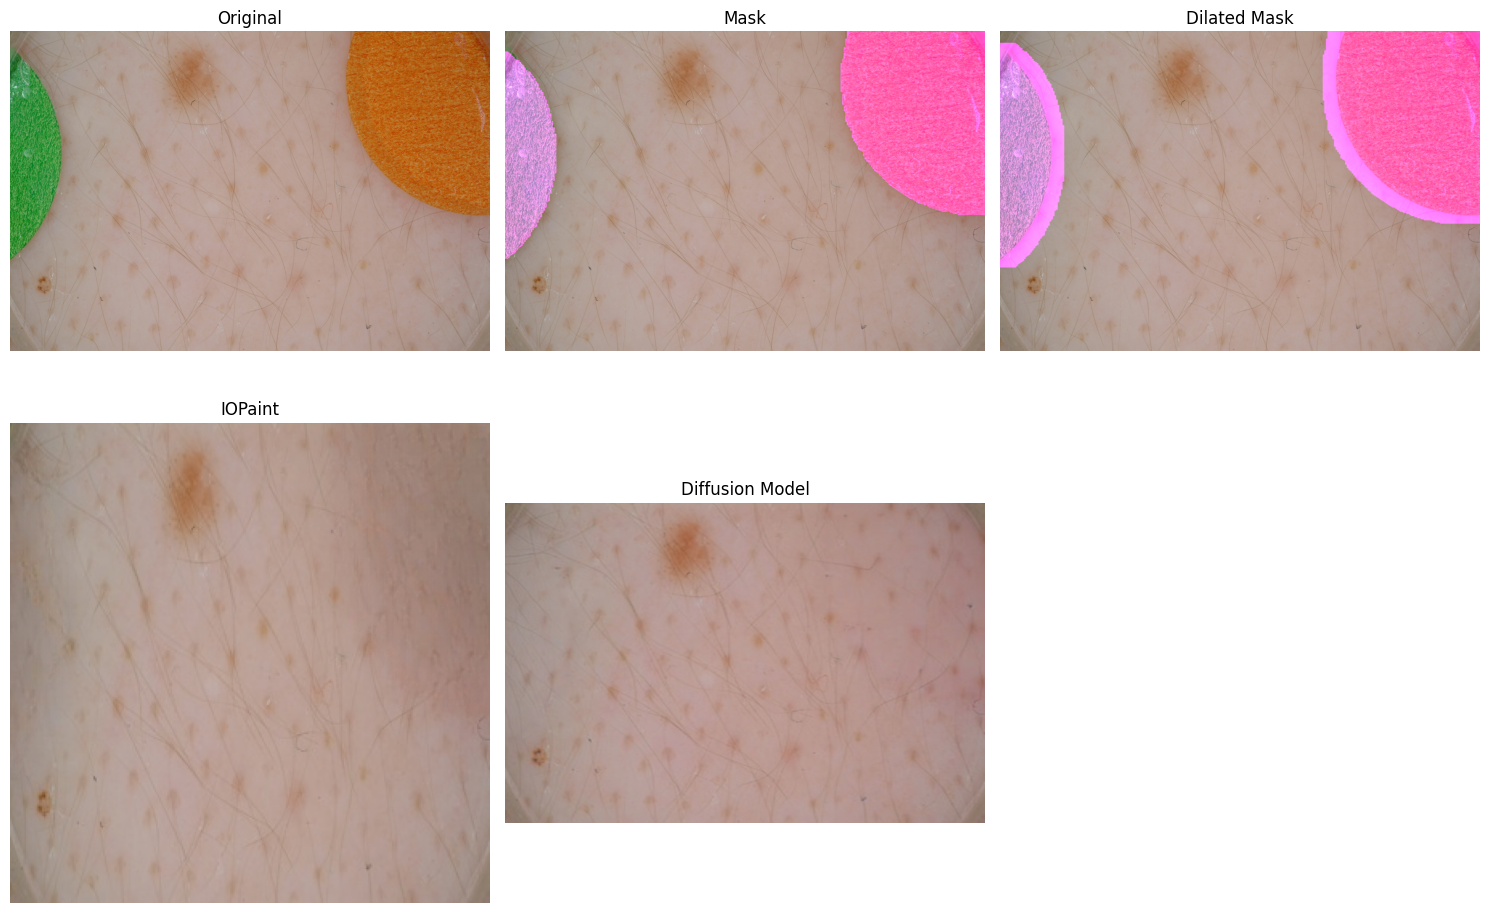

 86%|████████▌ | 6/7 [01:52<00:18, 18.33s/it]2024-11-03 15:50:22.791 | INFO     | iopaint.runtime:setup_model_dir:80 - Model directory: /root/.cache
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.10/site-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")
/usr/local/lib/python3.10/site-packages/iopaint/model/ldm.py:279: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @torch.cud

  Batch processing... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 1/1 0:00:0000:00


  0%|          | 0/24 [00:00<?, ?it/s]

Image: ISIC_0009040.jpg


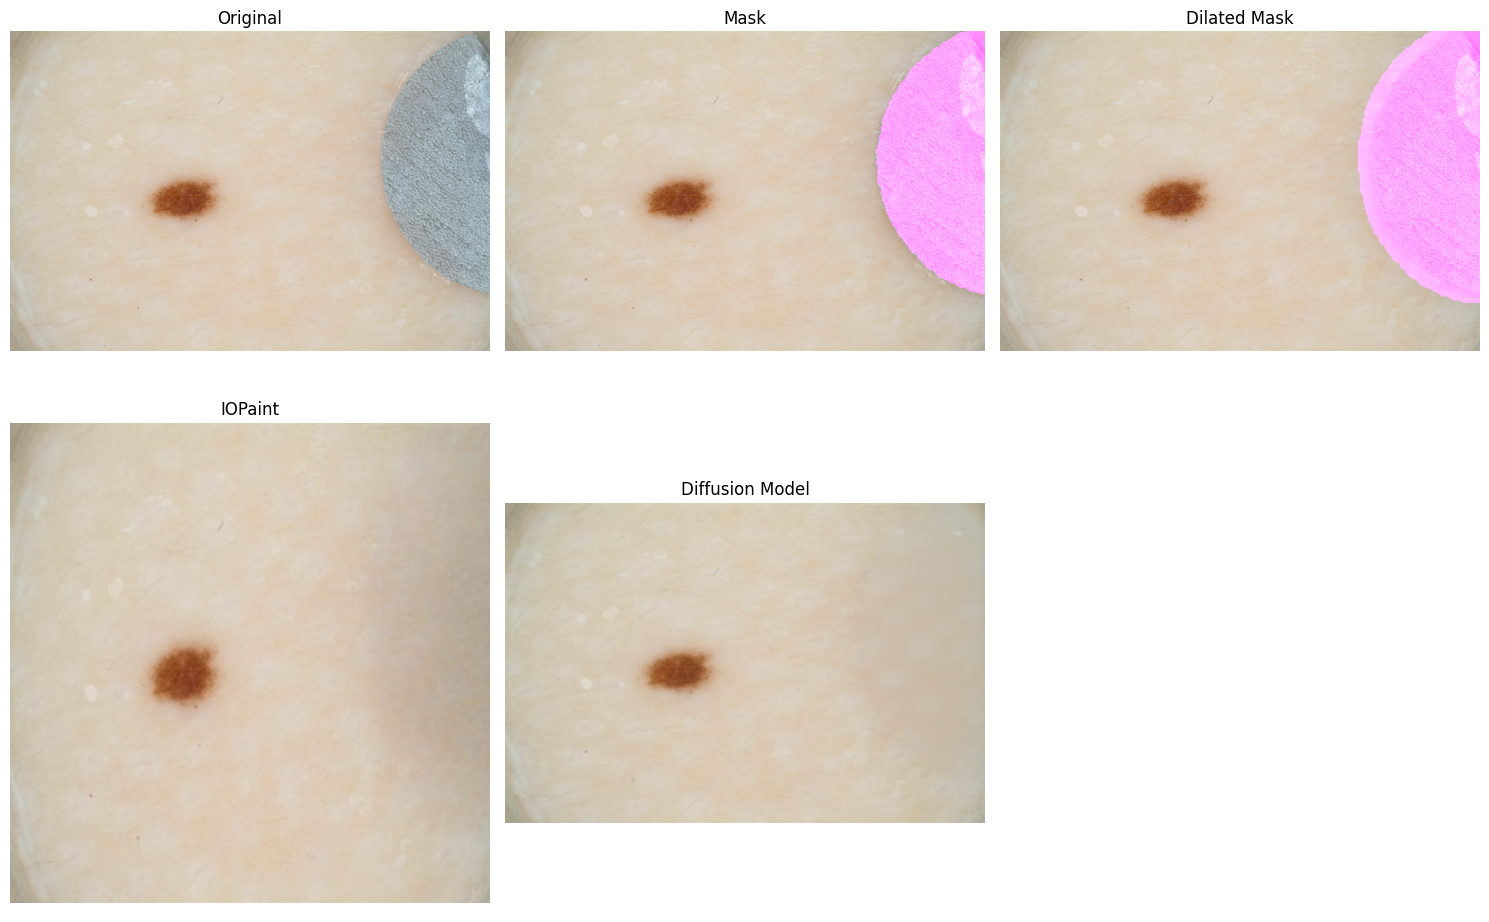

100%|██████████| 7/7 [02:10<00:00, 18.58s/it]


In [5]:
kernel_size = 5
iterations = 5
output_dir = f"/workspace/home/pipeline_outputs/ISIC2019"
save_dir = f"{output_dir}/thesis_images"

for i, mask_dict in enumerate(tqdm(segmentation_masks)):
    # result 1: inpaint with iopaint
    # result 2: inpaint diffusion model with result 1 as input
    
    result1, result2 = inpaint_instance_iopaint_lama_sdxl(
        mask_dict,
        dataset["raw_path"],
        prompt,
        pipe,
        generator,
        kernel_size=kernel_size,
        iterations=iterations,
    )

    # visualize output
    print(f"Image: {mask_dict['file_name']}")
    img = Image.open(images[i]['file_path']) 
    mask = Image.open(mask_dict['file_path']).convert("L").point(lambda x: 255 if x > 128 else 0)
    dilated_mask = dilate_mask(mask, kernel_size=kernel_size, iterations=iterations)
    mask = mask.resize(img.size)
    dilated_mask = dilated_mask.resize(img.size)
    mask_on_img = mask_on_image(img, mask)
    dilated_mask_on_img = mask_on_image(img, dilated_mask)
    plot_grid([img, mask_on_img, dilated_mask_on_img, result1, result2], label=["Original", "Mask", "Dilated Mask", "IOPaint", "Diffusion Model"], ncols=3)
    result1.resize((400,400)).save(f"{save_dir}/lama_{mask_dict['file_name'].replace('.jpg', '.png')}")
    result2.resize((400,400)).save(f"{save_dir}/sdxl_{mask_dict['file_name'].replace('.jpg', '.png')}")
    dilated_mask_on_img.resize((400,400)).save(f"{save_dir}/dilated_mask_{segmentation_id}_{mask_dict['file_name']}")